[Python, Visually](https://johnfisher-ai.github.io/Python-Visual-Guides/) &nbsp;&rsaquo;&nbsp; [GeoPandas, Deep Dive](https://johnfisher-ai.github.io/Python-Visual-Guides/geopandas-deep-dive.html)

# Spatial Predicates


## What you will be able to do

Whether a station is inside a district, or whether two districts touch, is a question GeoPandas
answers for a whole column at once. You'll ask it row by row and against a single shape, and see how
the spatial index skips the pairs that cannot match.

## The idea

### The problem

The forecast office needs a handful of yes-or-no answers. Is station NS001 in the Mid district? Which
districts share a border with North, so that a warning issued there should go to them as well? Which
stations stand within 50 kilometers of Oslo? Every one of these asks how two shapes sit relative to
each other, and the answer is `True` or `False`.

Asked once, any of these is a single call. Asked for 300 stations against eight districts, it is 2,400
tests, and for a national register against thousands of small areas it becomes millions. Most of
those tests are wasted, since a station in the far north cannot be inside a district in the south, and
something has to rule those pairs out without testing each one in full.

### A formal definition

> A **spatial predicate** is a test of how two geometries relate that returns `True` or `False`.
> `within` asks whether one geometry lies inside another, `contains` asks the reverse, `intersects`
> whether they share any point at all, and `touches` whether they meet only on their boundaries. A
> **spatial index** stores the bounding box of every geometry in a layer, so that a query can find the
> few geometries whose boxes overlap a shape before any exact test runs.

### Why it works that way

A predicate called on a GeoSeries with a single shape tests every row against that shape and returns a
boolean Series, which filters a table the way a comparison of numbers does. Called with a second
GeoSeries, it pairs the rows by their index, as pandas arithmetic does, and tests row 0 against row 0,
row 1 against row 1. That pairing is useful when the rows match. When they do not, the answers are wrong, and
GeoPandas warns only if the two indexes differ.

The predicates also differ at the edges. A point on the line between two districts is not `within`
either, because `within` requires the point to be in a district's interior, and it `intersects` both.
Which predicate to use depends on what should happen to a shape on a border.

The spatial index is what keeps large tests fast. Comparing two boxes takes four comparisons of
numbers, while testing a point against a polygon of hundreds of corners takes a walk around its edges.
GeoPandas builds the index the first time it is needed, keeps it with the layer, and uses it inside
`sjoin` and its relatives.

### Where this shows up

Every spatial join is a predicate applied to many pairs at once, and the **Spatial Joins** notebook
builds on this one. Choosing which shapes to send a warning to, finding parcels that touch a road, and
checking that a point is inside the area a dataset covers are all predicates.

### What this notebook covers

- a predicate against one shape, and the reverse question
- which districts share a border
- which stations lie within a distance of a point
- predicates row by row between two columns
- the spatial index, its candidate pairs and its exact answers
- three mistakes made with predicates

### A first look

Before any of the detail, here is the whole idea in a few lines. There is nothing to run yet: read it,
and read the output underneath it. Everything from Setup onward is where you start running things.

```python
from shapely.geometry import Point, box

square = box(0, 0, 2, 2)
for point in [Point(1, 1), Point(2, 1), Point(3, 1)]:
    print(point.wkt, "within:", point.within(square), "| intersects:", point.intersects(square))
```

```
POINT (1 1) within: True | intersects: True
POINT (2 1) within: False | intersects: True
POINT (3 1) within: False | intersects: False
```

The first point is inside the square, the second lies on its right edge, and the third is outside.
`within` counts only the first, and `intersects` counts the point on the edge as well.

## Setup

Four libraries for the tables and the geometry, Matplotlib for the map, and two tools from the
standard library.

- `warnings` catches the warning in Common errors, so that the cell can print it
- `Path` finds the guide's copy of the country outlines, when the notebook runs beside it
- `numpy` and `pandas` build the made-up register and count the results
- `geopandas` runs the predicates and keeps the spatial index, and the cell prints its version
- `shapely` builds the made-up districts and a point on a border, and the cell prints its version
- `matplotlib.pyplot` draws the districts' bounding boxes

`countries` holds the outlines of the Nordic countries. Made with Natural Earth. The outlines come
from Natural Earth's 1:50m map of the world's countries, which is in the public domain.

`stations` is the register of 300 weather stations in latitude and longitude, `named` is the five named
stations, and `districts` is the eight forecast districts in meters in UTM zone 33N. The stations and
the districts are made up, drawn from a fixed seed so that they are the same on every run.
`stations_m` is the register converted to the districts' CRS, so that the two can be compared.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import shapely
import matplotlib.pyplot as plt

COUNTRIES_URL = ("https://raw.githubusercontent.com/johnfisher-ai/Python-Visual-Guides/main/data/nordic-countries.geojson")
local_copy = Path("../../data/nordic-countries.geojson")
countries = gpd.read_file(local_copy if local_copy.exists() else COUNTRIES_URL)


weather_stations = pd.DataFrame({
    "name": ["Bergen", "Oslo", "Svalbard", "Tromso", "Kirkenes"],
    "latitude": [60.39, 59.91, 78.22, 69.65, 69.73],
    "longitude": [5.32, 10.75, 15.65, 18.96, 30.05],
})


def mainland_norway():
    """Norway's outline south of 74 degrees north, without Svalbard, in UTM zone 33N."""
    parts = countries[countries["ADMIN"] == "Norway"].to_crs(25833).explode()
    return parts[parts.geometry.bounds["maxy"] < 8_200_000].union_all()


def station_network(n=300, seed=2026):
    """A made-up register of weather stations on mainland Norway, one row each."""
    rng = np.random.default_rng(seed)
    land = mainland_norway()
    x_min, y_min, x_max, y_max = land.bounds
    east, north = [], []
    while len(east) < n:
        x, y = rng.uniform(x_min, x_max), rng.uniform(y_min, y_max)
        if land.contains(shapely.Point(x, y)):
            east.append(x)
            north.append(y)
    lonlat = gpd.GeoSeries(gpd.points_from_xy(east, north), crs=25833).to_crs(4326)
    return pd.DataFrame({
        "station": [f"NS{i:03d}" for i in range(1, n + 1)],
        "latitude": lonlat.y.round(4).to_numpy(), "longitude": lonlat.x.round(4).to_numpy(),
        "elevation_m": np.clip(rng.gamma(1.6, 220, n), 2, 1900).round(0).astype(int),
        "owner": rng.choice(["met", "road", "airport", "private"], n, p=[0.4, 0.3, 0.1, 0.2]),
        "installed": rng.integers(1950, 2025, n),
    })


DISTRICT_CENTERS = {"South": (8.0, 58.6), "East": (10.8, 60.5), "West": (6.0, 60.8), "Mid": (11.0, 63.6),
                    "North": (14.5, 67.0), "Far North": (19.0, 69.4), "Northeast": (25.5, 70.0),
                    "Svalbard": (16.0, 78.5)}


def forecast_districts():
    """Eight made-up forecast districts that cover Norway, in UTM zone 33N."""
    norway = countries[countries["ADMIN"] == "Norway"].to_crs(25833).geometry.iloc[0]
    centers = gpd.GeoSeries(gpd.points_from_xy(*zip(*DISTRICT_CENTERS.values())), crs=4326).to_crs(25833)
    cells = shapely.voronoi_polygons(shapely.MultiPoint(list(centers)),
                                     extend_to=shapely.box(*norway.buffer(200_000).bounds)).geoms
    names = [next(name for name, center in zip(DISTRICT_CENTERS, centers) if cell.contains(center))
             for cell in cells]
    districts = gpd.GeoDataFrame({"district": names}, geometry=[cell.intersection(norway) for cell in cells],
                                 crs=25833)
    return districts.set_index("district").loc[list(DISTRICT_CENTERS)].reset_index()


network = station_network()
stations = gpd.GeoDataFrame(
    network, geometry=gpd.points_from_xy(network["longitude"], network["latitude"]), crs=4326
)


named = gpd.GeoDataFrame(
    weather_stations,
    geometry=gpd.points_from_xy(weather_stations["longitude"], weather_stations["latitude"]),
    crs=4326,
)


districts = forecast_districts()
stations_m = stations.to_crs(districts.crs)
print("geopandas", gpd.__version__, "| shapely", shapely.__version__, "|", len(stations), "made-up stations,",
      len(districts), "made-up districts")

geopandas 1.2.0 | shapely 2.2.0 | 300 made-up stations, 8 made-up districts


## Worked examples

### A predicate against one shape

`by_name` is the districts with their names as the index, so that a district's shape can be picked by
name. `within` tests every station against the Mid district's shape and returns one boolean per
station.

In [2]:
by_name = districts.set_index("district")
mid = by_name.loc["Mid", "geometry"]
in_mid = stations_m.within(mid)
print(type(in_mid).__name__, in_mid.dtype, len(in_mid))
print("within Mid:", in_mid.sum(), "| intersects Mid:", stations_m.intersects(mid).sum())

Series bool 300
within Mid: 69 | intersects Mid: 69


The result is a Series of 300 booleans, so `sum` counts the stations inside, 69, and the same Series
filters the register.

In [3]:
stations_m[in_mid][["station", "owner", "elevation_m"]].head()

,station,owner,elevation_m
1,NS002,met,325
4,NS005,road,291
10,NS011,met,53
12,NS013,met,273
14,NS015,met,12


### The reverse question

`contains` asks the same thing from the polygon's side. Called on the districts with one station's
point, it says which district holds that station.

In [4]:
first = stations_m.geometry.iloc[0]
holds = by_name.contains(first)
print(holds.to_string())
print(stations_m["station"].iloc[0], "is in", holds[holds].index[0])

district
South        False
East          True
West         False
Mid          False
North        False
Far North    False
Northeast    False
Svalbard     False
NS001 is in East


### Which districts share a border

`touches` is true when two shapes meet on their boundaries and their interiors do not overlap. The
cell tests every pair of districts.

In [5]:
neighbors = {
    name: [other for other in by_name.index if other != name and shape.touches(by_name.loc[other, "geometry"])]
    for name, shape in by_name.geometry.items()
}
for name, others in neighbors.items():
    print(f"{name:10}", ", ".join(others) or "none")

South      East, West
East       South, West, Mid
West       South, East, Mid
Mid        East, West, North
North      Mid, Far North
Far North  North, Northeast
Northeast  Far North
Svalbard   none


South borders East and West, and Northeast only Far North. Svalbard touches no district, since the sea
separates it from the mainland. The districts were cut from one outline, so wherever two of them meet
they share an edge and nothing more, and `intersects` gives the same pairs.

In [6]:
overlap = {
    name: [other for other in by_name.index if other != name and shape.intersects(by_name.loc[other, "geometry"])]
    for name, shape in by_name.geometry.items()
}
print("same pairs from intersects:", overlap == neighbors)

same pairs from intersects: True


### Within a distance

`dwithin` is true when two shapes are no farther apart than a given distance, in the CRS's units. In
UTM zone 33N that is meters.

In [7]:
oslo = named.to_crs(districts.crs).geometry.iloc[1]
near_oslo = stations_m.dwithin(oslo, 50_000)
print(near_oslo.sum(), "stations within 50 km of Oslo:", ", ".join(stations_m.loc[near_oslo, "station"]))

5 stations within 50 km of Oslo: NS006, NS154, NS172, NS221, NS285


### Row by row between two columns

A predicate given a second GeoSeries pairs the rows by index. Here `home` holds, for each station, the
shape of the district a spatial join gave it, with the same index as the stations, so `within` tests
each station against its own district.

In [8]:
assigned = gpd.sjoin(stations_m, districts, how="left")["district"]
home = gpd.GeoSeries(by_name.geometry.loc[assigned].to_numpy(), index=stations_m.index, crs=districts.crs)
print("stations within their own district:", stations_m.within(home).sum(), "of", len(stations_m))

stations within their own district: 300 of 300


### The spatial index

A layer's `sindex` is its spatial index. The spatial join above already built one for `districts`,
so the cell works on `layer`, a fresh copy of the districts, which has none until the first query
builds it. `query` with no predicate returns every pair whose bounding boxes overlap, as two rows of
positions, with the stations' positions on top and the districts' below.

In [9]:
layer = districts.copy()
print("index built yet:", layer.has_sindex)
candidates = layer.sindex.query(stations_m.geometry, sort=True)
print("index built yet:", layer.has_sindex)
print(candidates.shape)
print(candidates[:, :6])

index built yet: False
index built yet: True
(2, 373)
[[0 1 2 3 4 5]
 [1 3 6 5 3 1]]


The first column says that station 0 falls in district 1's box. There are 373 candidate pairs for 300
stations, because the districts' boxes overlap, and a station in an overlap is a candidate for each
box it is in.

In [10]:
exact = districts.sindex.query(stations_m.geometry, predicate="within", sort=True)
per_station = np.bincount(candidates[0], minlength=len(stations_m))
print("candidate pairs:", candidates.shape[1], "| exact pairs:", exact.shape[1])
print("stations in more than one box:", (per_station > 1).sum())
print("most districts for one station:", np.bincount(exact[0]).max())
print("predicates the index accepts:", sorted(name for name in districts.sindex.valid_query_predicates if name))

candidate pairs: 373 | exact pairs: 300
stations in more than one box: 68
most districts for one station: 1
predicates the index accepts: ['contains', 'contains_properly', 'covered_by', 'covers', 'crosses', 'dwithin', 'intersects', 'overlaps', 'touches', 'within']


With `predicate="within"` the index finds the candidates by box and then runs the exact test on those
pairs alone, leaving exactly one district for each of the 300 stations. The 68 stations that sat in
two or more boxes were tested against each of them, and every other station against one district,
373 tests in place of 2,400.

The map shows why the boxes overlap. A district's box is the smallest rectangle around it, and where two districts
meet along a slanting line, each box reaches across the line into its neighbor.

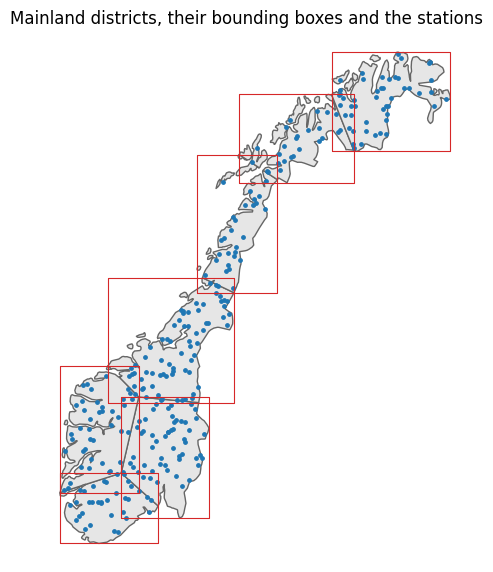

In [11]:
fig, ax = plt.subplots(figsize=(6, 7))
districts.plot(ax=ax, color="0.9", edgecolor="0.4")
districts.envelope.boundary.plot(ax=ax, color="tab:red", linewidth=0.8)
stations_m.plot(ax=ax, color="tab:blue", markersize=6)
ax.set_axis_off()
ax.set_xlim(-200_000, 1_200_000)
ax.set_ylim(6_400_000, 7_950_000)
ax.set_title("Mainland districts, their bounding boxes and the stations")
plt.show()

## Your turn

Five tasks. Write your answer in the cell under each task and run it.

Try a task before you look at its answer. Reading a solution teaches you much less than
getting there yourself, even slowly.

When you are ready: [**open the solutions notebook**](https://colab.research.google.com/github/johnfisher-ai/Python-Visual-Guides/blob/main/notebooks/geopandas-deep-dive/07-spatial-predicates-solutions.ipynb).

**1.** Count the stations within each district with `within`, and print the counts in the districts' order.

In [12]:
# your code here

**2.** Print the districts that touch the North district.

In [13]:
# your code here

**3.** Count the stations within 100 km of Bergen with `dwithin`.

In [14]:
# your code here

**4.** Use `districts.sindex.query` with `predicate="intersects"` to find which district each of the five named stations falls in, and print the station and district names.

In [15]:
# your code here

**5.** Find the stations that fall in more than one district's bounding box, and print how many of them each district holds by `within`.

In [16]:
# your code here

## Common errors

### `UserWarning: The indices of the left and right GeoSeries' are not equal, and therefore they will be aligned (reordering and/or introducing missing values) before executing the operation.`

The aim is to ask which district contains each station, and the code passes the stations' points to
the districts' `contains`.

In [17]:
points_m = stations.to_crs(districts.crs)
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always", UserWarning)
    paired = districts.contains(points_m.geometry)
for warning in caught:
    print(f"{warning.category.__name__}: {str(warning.message).split('. ')[0]}.")
print(len(paired), "results,", paired.sum(), "True")

300 results, 0 True


Given a GeoSeries, `contains` pairs rows by index. The districts have the index 0 to 7 and the
stations 0 to 299, so it tests district 0 against station 0, district 1 against station 1, and so on,
fills the 292 rows with no district with `False`. None of the eight paired stations happens to lie in
the district it was paired with, so none of the 300 results is `True`. The warning
says that rows were paired up by index. To test every station against every district, use a spatial
join, or the spatial index.

In [18]:
pairs = districts.sindex.query(points_m.geometry, predicate="within")
print(len(np.unique(pairs[0])), "stations matched to a district")

300 stations matched to a district


### No error, and no station within the Mid district

In [19]:
mid_shape = districts.set_index("district").loc["Mid", "geometry"]
print("within Mid, in degrees:", stations.within(mid_shape).sum())
print("within Mid, in meters: ", stations.to_crs(districts.crs).within(mid_shape).sum())

within Mid, in degrees: 0
within Mid, in meters:  69


`mid_shape` is a single Shapely polygon, and a Shapely geometry carries no CRS, so GeoPandas has
nothing to compare the stations' CRS with and warns of nothing. The stations are in degrees, numbers
no larger than 72, and the district is in meters, numbers in the hundreds of thousands and millions, so
no station lands inside it. Convert the stations to the districts' CRS before testing, as the second
line does.

### No error, and a point within neither district

Where East and Mid meet, they share an edge. The cell takes a corner of that edge and asks both
districts about it.

In [20]:
shapes = districts.set_index("district").geometry
edge = shapes["East"].intersection(shapes["Mid"])
on_border = shapely.Point(shapely.get_coordinates(edge)[1])
print("shared edge:", edge.geom_type)
for name in ["East", "Mid"]:
    shape = shapes[name]
    print(f"{name:4} within: {on_border.within(shape)} | intersects: {on_border.intersects(shape)} "
          f"| covered_by: {on_border.covered_by(shape)}")

shared edge: LineString
East within: False | intersects: True | covered_by: True
Mid  within: False | intersects: True | covered_by: True


The point lies on the boundary of both districts and in the interior of neither, so `within` is
`False` for both and a count by `within` drops it. `intersects` and `covered_by` count a point on the
boundary, and give `True` for both districts, so a count with either one counts the point twice.
Decide which district a border point belongs to, or use `intersects` and keep the first match.

## Recap

- You can test every row of a GeoSeries against one shape with `within`, `contains`, `intersects`,
  `touches` and `dwithin`, and filter with the result.
- You can find which shapes share a border.
- You can test two GeoSeries row by row, and know that their rows are paired by index.
- You can query the spatial index for candidate pairs, and for exact pairs with a predicate.
- You can choose a predicate by what it does with a point on a border.

## What is next

The **Spatial Joins** notebook uses these predicates to attach to every station the attributes of the
district it falls in, for whole tables at once.

---

&#8592; **Previous:** [Measuring Distance and Area](https://colab.research.google.com/github/johnfisher-ai/Python-Visual-Guides/blob/main/notebooks/geopandas-deep-dive/06-measuring-distance-and-area.ipynb)  &nbsp;·&nbsp;  [GeoPandas, Deep Dive Notebooks](https://johnfisher-ai.github.io/Python-Visual-Guides/geopandas-deep-dive.html)  &nbsp;·&nbsp;  **Next:** [Spatial Joins](https://colab.research.google.com/github/johnfisher-ai/Python-Visual-Guides/blob/main/notebooks/geopandas-deep-dive/08-spatial-joins.ipynb) &#8594;
